# Supplementary Figure S14a. Indirect effects within the chr16 KNOP1 colocalization set (AD CoS 77)

Mediation analysis within AD colocalization event CoS 77 (lead variant chr16:19696874:A:G): columns are the cis-eGene mediators (KNOP1 in eight contexts and IQCK in astrocytes), rows the 50 colocalized *trans*-eGenes / *trans*-ePrograms (recipient context in brackets), ordered by the author's `outcome_rank` (microglial *trans*-eProgram 27, boxed, at the top). Colour is the raw (unstandardized) indirect effect estimate. Asterisks mark nominal donor-bootstrap p < 0.05 (`bootstrap_p`, 1000 bootstrap replicates, no multiple-testing correction): 66 of 450 cells. None of the 450 tests has global BH q < 0.05 (`BH_q_global`); 18 have BH q < 0.05 when corrected within each cis mediator (`BH_q_per_cis`).

Input: `data/Figure_S14a_KNOP1_mediation_heatmap.rds`


In [1]:
library(ggplot2)
d <- readRDS("data/Figure_S14a_KNOP1_mediation_heatmap.rds")
head(d)
c(n_cells = nrow(d), n_nominal_p05 = sum(d$bootstrap_p < 0.05),
  n_BH_global_05 = sum(d$BH_q_global < 0.05), n_BH_per_cis_05 = sum(d$BH_q_per_cis < 0.05))

,mediator_id,mediator_gene,mediator_context,mediator_index,mediator_label,outcome_id,outcome_type,outcome_symbol,outcome_context,plot_label,⋯,indirect_effect,ci_lower,ci_upper,bootstrap_p,BH_q_global,BH_q_per_cis,fiml_p,n_bootstrap,n_complete,nominal_mark
,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>
1,KNOP1|AC,KNOP1,AC,1,KNOP1 (AC),trans-eGene|BAG1|AC,trans-eGene,BAG1,AC,BAG1 (AC),⋯,-0.05319044,-0.096333905,-0.007667577,0.025974026,0.2656434,0.2797203,0.007725309,1000,548,*
2,KNOP1|AC,KNOP1,AC,1,KNOP1 (AC),trans-eGene|MAPKAP1|AC,trans-eGene,MAPKAP1,AC,MAPKAP1 (AC),⋯,-0.03727728,-0.068994131,-0.008623597,0.005994006,0.1332001,0.2797203,0.003680824,1000,548,*
3,KNOP1|AC,KNOP1,AC,1,KNOP1 (AC),trans-eGene|RPLP1|AC,trans-eGene,RPLP1,AC,RPLP1 (AC),⋯,-0.06018188,-0.103539727,-0.016763393,0.011988012,0.1798202,0.2797203,0.002332016,1000,548,*
4,KNOP1|AC,KNOP1,AC,1,KNOP1 (AC),trans-eGene|CILP2|AC,trans-eGene,CILP2,AC,CILP2 (AC),⋯,0.05817357,-0.085348343,0.192210559,0.361638362,0.7200117,0.7472527,0.232537062,1000,548,
5,KNOP1|AC,KNOP1,AC,1,KNOP1 (AC),trans-eGene|NOP9|AC,trans-eGene,NOP9,AC,NOP9 (AC),⋯,-0.01888323,-0.041519082,0.004053663,0.121878122,0.4684391,0.5527806,0.027217324,1000,548,
6,KNOP1|AC,KNOP1,AC,1,KNOP1 (AC),trans-eGene|RYR3|AC,trans-eGene,RYR3,AC,RYR3 (AC),⋯,0.07441036,-0.007983554,0.155942253,0.075924076,0.4036780,0.4745255,0.036066868,1000,548,


n_cells   n_nominal_p05  n_BH_global_05 n_BH_per_cis_05 
            450              66               0              18

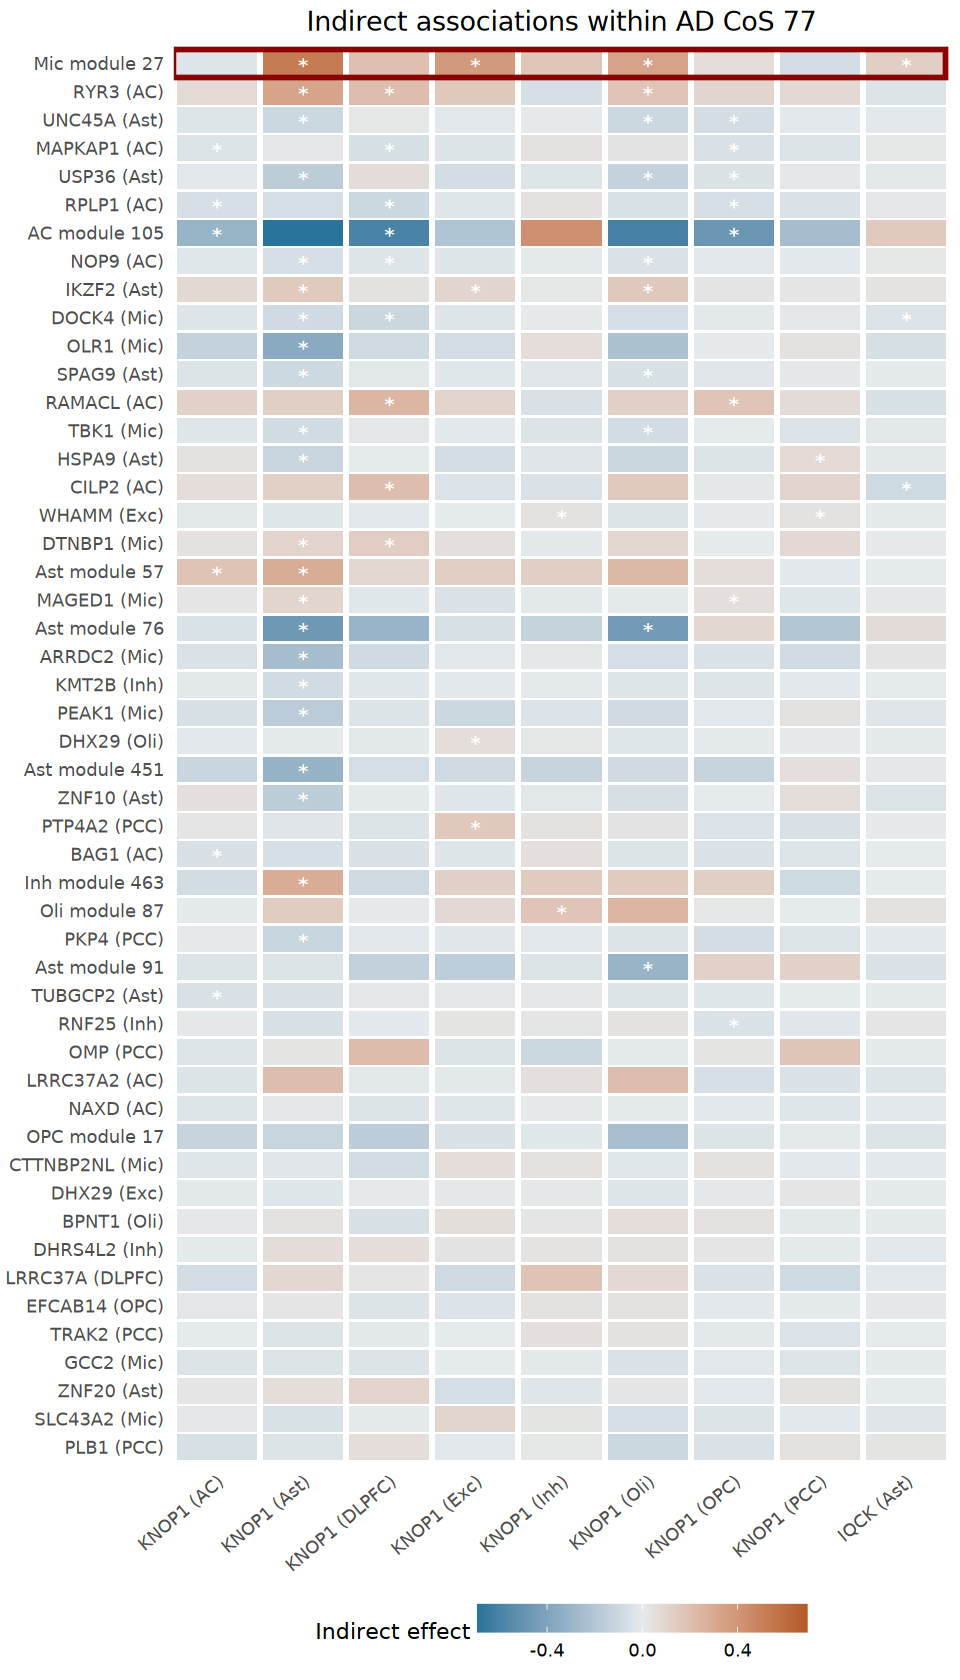

In [2]:
rk <- unique(d[, c("plot_label", "outcome_rank")])
rk <- rk[order(rk$outcome_rank), ]
d$plot_label <- factor(d$plot_label, levels = rev(rk$plot_label))
med <- unique(d[, c("mediator_index", "mediator_label")])
med <- med[order(med$mediator_index), ]
lim <- max(abs(d$indirect_effect))

p <- ggplot(d, aes(mediator_index, plot_label, fill = indirect_effect)) +
  geom_tile(width = 0.92, height = 0.87) +
  geom_text(aes(label = nominal_mark), colour = "white", size = 4.2, fontface = "bold", vjust = 0.65) +
  annotate("rect", xmin = 0.5, xmax = 9.46, ymin = nrow(rk) - 0.5, ymax = nrow(rk) + 0.5,
           fill = NA, colour = "darkred", linewidth = 1.2) +
  scale_fill_gradient2(low = "#28749A", mid = "#E5EAEC", high = "#B35A27", midpoint = 0,
                       limits = c(-lim, lim), name = "Indirect effect",
                       guide = guide_colourbar(barwidth = grid::unit(7, "cm"))) +
  scale_x_continuous(breaks = med$mediator_index, labels = med$mediator_label,
                     limits = c(0.5, 9.5), expand = c(0, 0)) +
  labs(title = "Indirect associations within AD CoS 77", x = NULL, y = NULL) +
  theme_minimal(base_size = 13) +
  theme(panel.grid = element_blank(), plot.title = element_text(hjust = 0.5),
        axis.text.x = element_text(angle = 40, hjust = 1), legend.position = "bottom")
options(repr.plot.width = 8, repr.plot.height = 14)
p